# M4 Exploratory Data Analysis - Earthquake & Seismic Activity Tracking Pipeline

**Research question.** In the project's global, latest-1,500 USGS snapshot of earthquakes with magnitude at least 2.5, how do earthquake magnitude and frequency vary with topographical elevation and geography?

This notebook is an exploratory snapshot analysis, not a model or a causal study. It uses UTC throughout and reads SQLite in immutable read-only mode.

In [1]:
from pathlib import Path
from urllib.parse import quote
import hashlib
import json
import sqlite3

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr, skew

# Major parameters - change choices here, not in hidden state.
ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
DB_PATH = (ROOT / "data" / "earthquake.db").resolve()
FIGURE_DIR = ROOT / "figures"
FIGURE_DIR.mkdir(exist_ok=True)
RANDOM_SEED = 20261115
BOOTSTRAP_REPS = 20_000
EXPECTED_USGS_EVENTS = 1500
MAGNITUDE_FLAGS_REPORTED = ("ok", "unusual_high")
MAGNITUDE_FLAGS_STRICT = ("ok",)
ELEVATION_FLAG = "ok"
COORDINATE_FLAG = "ok"
MIN_GROUP_N = 10
MIN_DAILY_GROUP_N = 5
MIN_ELEVATION_COVERAGE = 0.90
HISTOGRAM_WIDTHS_TESTED = (0.25, 0.50, 1.00)
HISTOGRAM_WIDTH_SELECTED = 0.50
SPATIAL_GRID_DEGREES = 10
COMPARISONS_EXPLORED = 3

def sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()

DB_HASH_BEFORE = sha256(DB_PATH)
uri = f"file:{quote(DB_PATH.as_posix(), safe='/:')}?mode=ro&immutable=1"
con = sqlite3.connect(uri, uri=True)

def sql_frame(query, params=()):
    return pd.read_sql_query(query, con, params=params)

print({
    "database": str(DB_PATH), "db_sha256_before": DB_HASH_BEFORE,
    "seed": RANDOM_SEED, "bootstrap_reps": BOOTSTRAP_REPS,
    "reported_magnitude_flags": MAGNITUDE_FLAGS_REPORTED,
    "coverage_rule": f"group n >= {MIN_GROUP_N}; elevation coverage >= {MIN_ELEVATION_COVERAGE:.0%}",
})

{'database': 'C:\\Users\\Yaşar\\Documents\\Codex\\2026-11-15\\files-mentioned-by-the-user-dse\\earthquake-seismic-pipeline\\data\\earthquake.db', 'db_sha256_before': '27b390687164337d9685d3fc58b9fd95881b777a0b43ce1c9080711b9c0b31e3', 'seed': 20261115, 'bootstrap_reps': 20000, 'reported_magnitude_flags': ('ok', 'unusual_high'), 'coverage_rule': 'group n >= 10; elevation coverage >= 90%'}


## 2.1 Raw versus cleaned: the key number

The key numerical measure is mean earthquake magnitude because it answers the original question about average event severity while retaining the whole thresholded snapshot. The raw query uses the M2 event snapshots exactly as loaded. The cleaned query uses the M3 quality filter selected for reporting and the deduplicated clean layer.

In [2]:
RAW_KEY_SQL = """
SELECT COUNT(*) AS n, AVG(magnitude) AS mean_magnitude
FROM earthquake_events
"""
CLEAN_KEY_SQL = """
SELECT COUNT(*) AS n, AVG(magnitude) AS mean_magnitude
FROM earthquake_events_clean
WHERE magnitude_flag IN (?, ?)
"""
raw_key = sql_frame(RAW_KEY_SQL)
clean_key = sql_frame(CLEAN_KEY_SQL, MAGNITUDE_FLAGS_REPORTED)
print("RAW SQL:\n", RAW_KEY_SQL.strip())
display(raw_key.round(4))
print("CLEAN SQL:\n", CLEAN_KEY_SQL.strip(), "\nparams =", MAGNITUDE_FLAGS_REPORTED)
display(clean_key.round(4))
print(f"Difference (clean - raw): {clean_key.mean_magnitude.iloc[0] - raw_key.mean_magnitude.iloc[0]:.4f} magnitude units")

RAW SQL:
 SELECT COUNT(*) AS n, AVG(magnitude) AS mean_magnitude
FROM earthquake_events


,n,mean_magnitude
0,1500,3.8873


CLEAN SQL:
 SELECT COUNT(*) AS n, AVG(magnitude) AS mean_magnitude
FROM earthquake_events_clean
WHERE magnitude_flag IN (?, ?) 
params = ('ok', 'unusual_high')


,n,mean_magnitude
0,1500,3.8873


Difference (clean - raw): 0.0000 magnitude units


The two results are expected to differ only if duplicate retrieval snapshots or invalid magnitudes exist. Equality is itself a result: this recovered one-snapshot dataset has no duplicate event IDs and no invalid magnitudes. The clean layer remains necessary because it makes those decisions explicit and reproducible.

## 2.2 The question and the summary that answers it

The primary summary is mean magnitude by elevation band, with *n* beside every estimate. Magnitude is continuous and the sample is thresholded at 2.5, so the mean answers the average-severity question but is interpreted alongside the median, which is less sensitive to tails. Bands are fixed scientific categories rather than data-dependent quantiles: at/below sea level, lowland (0-500 m), and highland (>500 m).

In [3]:
EVENT_SQL = """
SELECT e.event_id, e.magnitude, e.magnitude_flag, e.place, e.event_time,
       l.latitude, l.longitude, l.elevation, l.elevation_flag, l.coordinate_flag
FROM earthquake_events_clean AS e
JOIN elevation_locations_clean AS l ON e.location_source_id = l.source_id
WHERE e.magnitude_flag IN (?, ?)
  AND l.elevation_flag = ?
  AND l.coordinate_flag = ?
"""
events = sql_frame(EVENT_SQL, (*MAGNITUDE_FLAGS_REPORTED, ELEVATION_FLAG, COORDINATE_FLAG))
events["event_time"] = pd.to_datetime(events["event_time"], utc=True)
events["elevation_band"] = pd.cut(
    events["elevation"], [-np.inf, 0, 500, np.inf],
    labels=["At/below sea level", "Lowland (0-500 m)", "Highland (>500 m)"],
    include_lowest=True,
)
group_summary = events.groupby("elevation_band", observed=False)["magnitude"].agg(
    n="count", mean="mean", median="median", maximum="max"
).reset_index()
group_summary["mean_rank"] = group_summary["mean"].rank(ascending=False, method="min").astype(int)
group_summary["median_rank"] = group_summary["median"].rank(ascending=False, method="min").astype(int)
display(group_summary.round(3))
print("Rankings change?", not group_summary.mean_rank.equals(group_summary.median_rank))

,elevation_band,n,mean,median,maximum,mean_rank,median_rank
0,At/below sea level,1010,3.991,4.3,6.8,1,1
1,Lowland (0-500 m),188,3.482,3.1,5.7,3,3
2,Highland (>500 m),302,3.793,4.1,7.0,2,2


Rankings change? False


## 2.3 Shape

Three bin widths (0.25, 0.50, 1.00 magnitude units) are checked. The selected 0.50-unit width is close to the Freedman-Diaconis suggestion for this snapshot, uses interpretable half-magnitude steps, and avoids the noise of 0.25 and smoothing of 1.00. The ECDF complements the histogram by avoiding bin-edge sensitivity.

Freedman-Diaconis width: 0.297


,width,approx_bins
0,0.25,18
1,0.50,9
2,1.00,5


{'skewness': -0.035, 'minimum': np.float64(2.5), 'maximum': np.float64(7.0), 'p90': np.float64(5.0)}


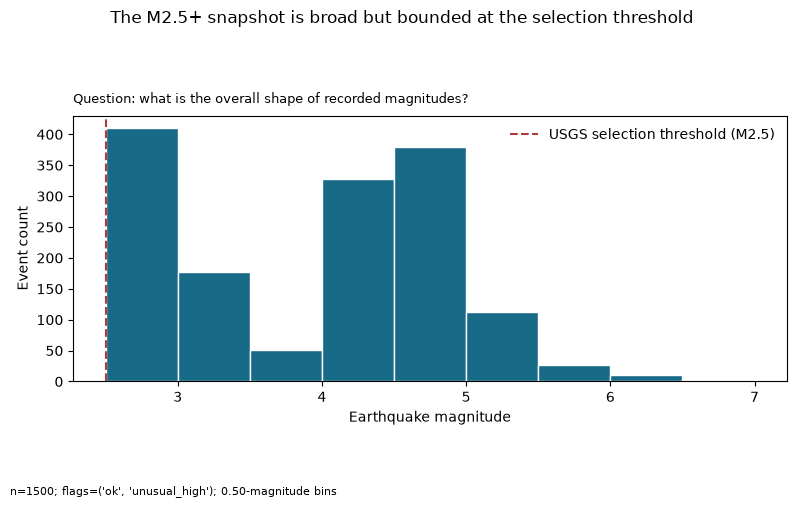

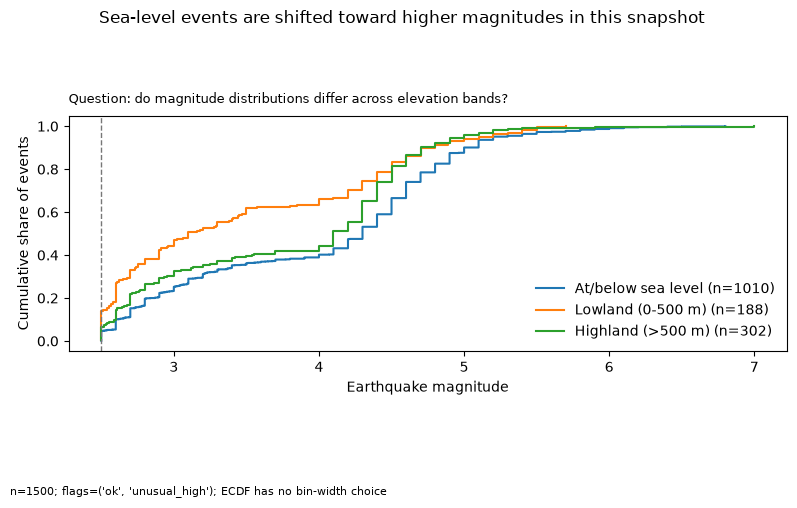

In [4]:
iqr = events.magnitude.quantile(0.75) - events.magnitude.quantile(0.25)
fd_width = 2 * iqr / np.cbrt(len(events))
bin_check = pd.DataFrame({
    "width": HISTOGRAM_WIDTHS_TESTED,
    "approx_bins": [int(np.ceil((events.magnitude.max() - events.magnitude.min()) / w)) for w in HISTOGRAM_WIDTHS_TESTED],
})
print(f"Freedman-Diaconis width: {fd_width:.3f}")
display(bin_check)

lower = np.floor(events.magnitude.min() / HISTOGRAM_WIDTH_SELECTED) * HISTOGRAM_WIDTH_SELECTED
upper = np.ceil(events.magnitude.max() / HISTOGRAM_WIDTH_SELECTED) * HISTOGRAM_WIDTH_SELECTED
bins = np.arange(lower, upper + HISTOGRAM_WIDTH_SELECTED, HISTOGRAM_WIDTH_SELECTED)
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(events.magnitude, bins=bins, color="#176B87", edgecolor="white")
ax.axvline(2.5, color="#B33A3A", linestyle="--", label="USGS selection threshold (M2.5)")
fig.suptitle("The M2.5+ snapshot is broad but bounded at the selection threshold", y=.98)
ax.set_title("Question: what is the overall shape of recorded magnitudes?", loc="left", fontsize=9, pad=9)
ax.set(xlabel="Earthquake magnitude", ylabel="Event count")
ax.legend(frameon=False)
fig.text(0.01, 0.01, f"n={len(events)}; flags={MAGNITUDE_FLAGS_REPORTED}; 0.50-magnitude bins", fontsize=8)
fig.tight_layout(rect=(0, .12, 1, .91))
fig.savefig(FIGURE_DIR / "magnitude_histogram.png", dpi=180, bbox_inches="tight")

fig, ax = plt.subplots(figsize=(8, 5))
for band, frame in events.groupby("elevation_band", observed=True):
    values = np.sort(frame.magnitude.to_numpy())
    ax.step(values, np.arange(1, len(values) + 1) / len(values), where="post", label=f"{band} (n={len(values)})")
ax.axvline(2.5, color="#777777", linestyle="--", linewidth=1)
fig.suptitle("Sea-level events are shifted toward higher magnitudes in this snapshot", y=.98)
ax.set_title("Question: do magnitude distributions differ across elevation bands?", loc="left", fontsize=9, pad=9)
ax.set(xlabel="Earthquake magnitude", ylabel="Cumulative share of events")
ax.legend(frameon=False)
fig.text(0.01, 0.01, f"n={len(events)}; flags={MAGNITUDE_FLAGS_REPORTED}; ECDF has no bin-width choice", fontsize=8)
fig.tight_layout(rect=(0, .18, 1, .91))
fig.savefig(FIGURE_DIR / "magnitude_ecdf_by_elevation.png", dpi=180, bbox_inches="tight")

print({"skewness": round(float(skew(events.magnitude, bias=False)), 3),
       "minimum": events.magnitude.min(), "maximum": events.magnitude.max(),
       "p90": round(events.magnitude.quantile(.9), 3)})

The magnitude distribution is nearly symmetric in this selected sample, with a hard lower boundary created by the M2.5 API threshold. Values close to 2.5 are therefore censored from below; this analysis cannot describe smaller earthquakes or an unthresholded global distribution. The upper tail reaches M7.0 but contains no M8+ event.

## 2.4 Coverage, denominators and the flag filter

Earthquakes are events, not scheduled hourly measurements. Event coverage therefore means: returned records versus the API request limit, unique usable events versus loaded events, and usable elevations versus unique event coordinates. It does **not** mean 24 expected earthquakes per day. Main elevation-band summaries require at least 10 events and 90% usable elevation. Daily-by-band summaries require at least 5 events because finer cells are explicitly exploratory.

,component,actual,expected,coverage
0,USGS records returned,1500,1500,1.0
1,Distinct usable events,1500,1500,1.0
2,Usable elevations,1499,1499,1.0


Without coverage rule:


,elevation_band,n,mean,elevation_coverage,passes_rule
0,At/below sea level,1010,3.991,1.0,True
1,Lowland (0-500 m),188,3.482,1.0,True
2,Highland (>500 m),302,3.793,1.0,True


With coverage rule:


,elevation_band,n,mean,elevation_coverage,passes_rule
0,At/below sea level,1010,3.991,1.0,True
1,Lowland (0-500 m),188,3.482,1.0,True
2,Highland (>500 m),302,3.793,1.0,True


,event_time,elevation_band,n,mean,passes_daily_rule
0,2026-10-22 00:00:00+00:00,At/below sea level,33,4.033,True
1,2026-10-22 00:00:00+00:00,Lowland (0-500 m),5,3.176,True
2,2026-10-22 00:00:00+00:00,Highland (>500 m),27,4.557,True
3,2026-10-23 00:00:00+00:00,At/below sea level,37,4.153,True
4,2026-10-23 00:00:00+00:00,Lowland (0-500 m),8,3.616,True
...,...,...,...,...,...
70,2026-11-14 00:00:00+00:00,Lowland (0-500 m),7,3.586,True
71,2026-11-14 00:00:00+00:00,Highland (>500 m),8,3.719,True
72,2026-11-15 00:00:00+00:00,At/below sea level,14,4.039,True
73,2026-11-15 00:00:00+00:00,Lowland (0-500 m),6,3.217,True


,filter,n,mean_magnitude
0,ok only,1500,3.8873
1,ok + unusual_high,1500,3.8873


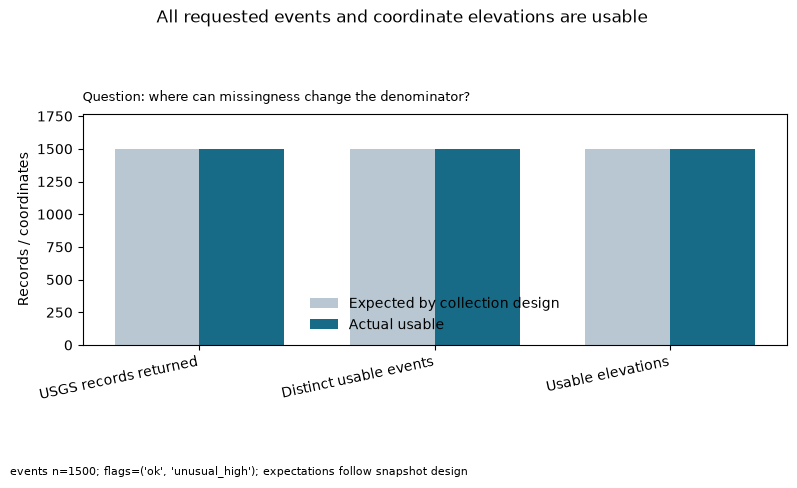

In [5]:
COVERAGE_SQL = """
SELECT
  (SELECT COUNT(*) FROM earthquake_events) AS loaded_event_snapshots,
  (SELECT COUNT(DISTINCT event_id) FROM earthquake_events) AS distinct_loaded_events,
  (SELECT COUNT(*) FROM earthquake_events_clean WHERE magnitude_flag IN (?, ?)) AS usable_clean_events,
  (SELECT COUNT(DISTINCT source_id) FROM elevation_locations_clean) AS coordinate_locations,
  (SELECT COUNT(*) FROM elevation_locations_clean WHERE elevation_flag = ?) AS usable_elevations
"""
coverage_row = sql_frame(COVERAGE_SQL, (*MAGNITUDE_FLAGS_REPORTED, ELEVATION_FLAG)).iloc[0]
coverage = pd.DataFrame({
    "component": ["USGS records returned", "Distinct usable events", "Usable elevations"],
    "actual": [coverage_row.loaded_event_snapshots, coverage_row.usable_clean_events, coverage_row.usable_elevations],
    "expected": [EXPECTED_USGS_EVENTS, coverage_row.distinct_loaded_events, coverage_row.coordinate_locations],
})
coverage["coverage"] = coverage.actual / coverage.expected
display(coverage)

main_rule = group_summary[["elevation_band", "n", "mean"]].copy()
main_rule["elevation_coverage"] = 1.0
main_rule["passes_rule"] = (main_rule.n >= MIN_GROUP_N) & (main_rule.elevation_coverage >= MIN_ELEVATION_COVERAGE)
print("Without coverage rule:")
display(main_rule.round(3))
print("With coverage rule:")
display(main_rule.loc[main_rule.passes_rule].round(3))

daily_band = events.groupby([events.event_time.dt.floor("D"), "elevation_band"], observed=True).magnitude.agg(n="count", mean="mean").reset_index()
daily_band["passes_daily_rule"] = daily_band.n >= MIN_DAILY_GROUP_N
display(daily_band.assign(mean=daily_band["mean"].round(3)))

strict = sql_frame("SELECT COUNT(*) AS n, AVG(magnitude) AS mean_magnitude FROM earthquake_events_clean WHERE magnitude_flag IN (?)", MAGNITUDE_FLAGS_STRICT)
inclusive = sql_frame("SELECT COUNT(*) AS n, AVG(magnitude) AS mean_magnitude FROM earthquake_events_clean WHERE magnitude_flag IN (?, ?)", MAGNITUDE_FLAGS_REPORTED)
flag_comparison = pd.concat([strict.assign(filter="ok only"), inclusive.assign(filter="ok + unusual_high")], ignore_index=True)
display(flag_comparison[["filter", "n", "mean_magnitude"]].round(4))

fig, ax = plt.subplots(figsize=(8, 4.8))
x = np.arange(len(coverage))
ax.bar(x - .18, coverage.expected, .36, label="Expected by collection design", color="#B8C7D1")
ax.bar(x + .18, coverage.actual, .36, label="Actual usable", color="#176B87")
ax.set_xticks(x, coverage.component, rotation=12, ha="right")
ax.set_ylim(0, max(coverage.expected) * 1.18)
fig.suptitle("All requested events and coordinate elevations are usable", y=.98)
ax.set_title("Question: where can missingness change the denominator?", loc="left", fontsize=9, pad=9)
ax.set(ylabel="Records / coordinates")
ax.legend(frameon=False)
fig.text(0.01, 0.01, f"events n={len(events)}; flags={MAGNITUDE_FLAGS_REPORTED}; expectations follow snapshot design", fontsize=8)
fig.tight_layout(rect=(0, .13, 1, .91))
fig.savefig(FIGURE_DIR / "coverage.png", dpi=180, bbox_inches="tight")

The inclusive filter is selected because `unusual_high` is a valid-event warning, not an invalidity flag. It gives the same result here because all 1,500 magnitudes are `ok`. The overall band coverage rule retains all three bands; the finer daily rule identifies any thin day-band cells separately.

## 2.5 Time

All timestamps are stored and analyzed in UTC, the reporting clock supplied by USGS. The first calendar day begins at 08:34 UTC on 22 October and the last ends at 15:52 UTC on 15 November, so both edge days are partial. The 23 dates between them are complete. Bars show counts without implying continuity, and no line is drawn beyond the retrieval boundaries.

{'first_event_utc': '2026-10-22 08:34:19+00:00', 'last_event_utc': '2026-11-15 15:52:42+00:00', 'first_day_partial': True, 'last_day_partial': True, 'complete_utc_days': ['2026-10-23', '2026-10-24', '2026-10-25', '2026-10-26', '2026-10-27', '2026-10-28', '2026-10-29', '2026-10-30', '2026-10-31', '2026-11-01', '2026-11-02', '2026-11-03', '2026-11-04', '2026-11-05', '2026-11-06', '2026-11-07', '2026-11-08', '2026-11-09', '2026-11-10', '2026-11-11', '2026-11-12', '2026-11-13', '2026-11-14']}


,events
event_time,
2026-10-22 00:00:00+00:00,65
2026-10-23 00:00:00+00:00,60
2026-10-24 00:00:00+00:00,135
2026-10-25 00:00:00+00:00,87
2026-10-26 00:00:00+00:00,71
2026-10-27 00:00:00+00:00,69
2026-10-28 00:00:00+00:00,84
2026-10-29 00:00:00+00:00,60
2026-10-30 00:00:00+00:00,60


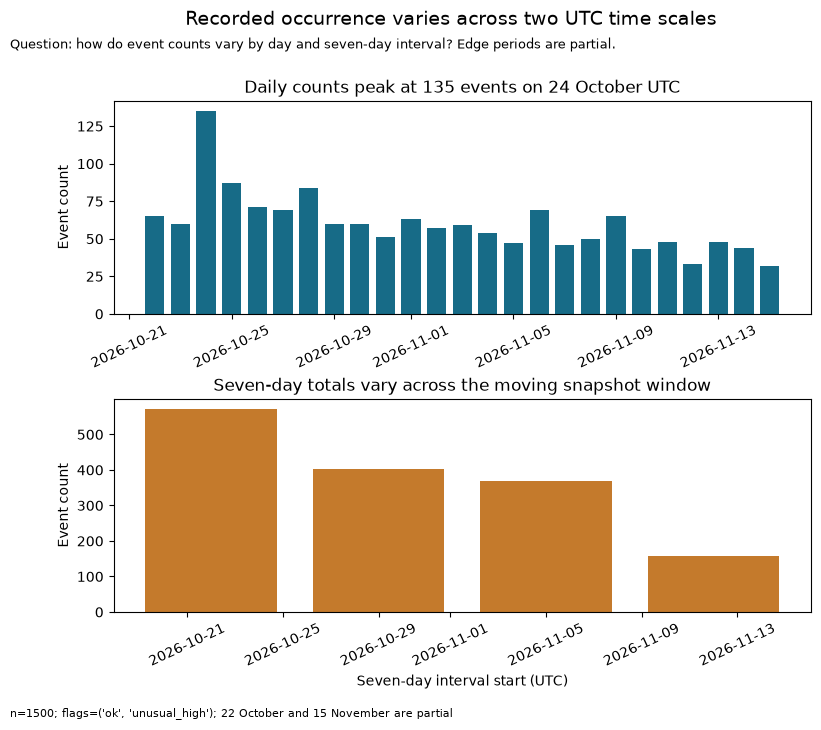

In [6]:
start, end = events.event_time.min(), events.event_time.max()
daily = events.set_index("event_time").resample("1D").size().rename("events")
weekly = events.set_index("event_time").resample("7D", origin="start_day").size().rename("events")
print({"first_event_utc": str(start), "last_event_utc": str(end),
       "first_day_partial": True, "last_day_partial": True,
       "complete_utc_days": [str(x.date()) for x in daily.index[1:-1]]})
display(daily.to_frame())

fig, axes = plt.subplots(2, 1, figsize=(9, 7))
axes[0].bar(daily.index, daily.values, width=.75, color="#176B87")
axes[0].set(title="Daily counts peak at 135 events on 24 October UTC", ylabel="Event count")
axes[1].bar(weekly.index, weekly.values, width=5.5, color="#C47A2C")
axes[1].set(title="Seven-day totals vary across the moving snapshot window", xlabel="Seven-day interval start (UTC)", ylabel="Event count")
fig.suptitle("Recorded occurrence varies across two UTC time scales", fontsize=14, y=.99)
fig.text(.01, .935, "Question: how do event counts vary by day and seven-day interval? Edge periods are partial.", fontsize=9)
fig.text(0.01, -0.02, f"n={len(events)}; flags={MAGNITUDE_FLAGS_REPORTED}; 22 October and 15 November are partial", fontsize=8)
fig.subplots_adjust(top=.86, bottom=.13, hspace=.40)
for axis in axes:
    axis.tick_params(axis="x", labelrotation=25)
fig.savefig(FIGURE_DIR / "temporal_counts_utc.png", dpi=180, bbox_inches="tight")

The snapshot spans about 24.3 days, enough to compare daily and seven-day counts but not enough to establish monthly or seasonal effects. No global calendar conclusion is defensible: day-to-day variation can arise from earthquake clustering, partial edge periods, and the latest-1,500 selection mechanism.

## 2.6 Relationships

The magnitude-elevation relationship is plotted before coefficients are calculated. Surface elevation is a coarse topographical covariate; many epicentres are offshore, so zero-metre Open-Meteo values may represent ocean surface rather than seafloor. Correlation does not imply that elevation causes earthquake magnitude.

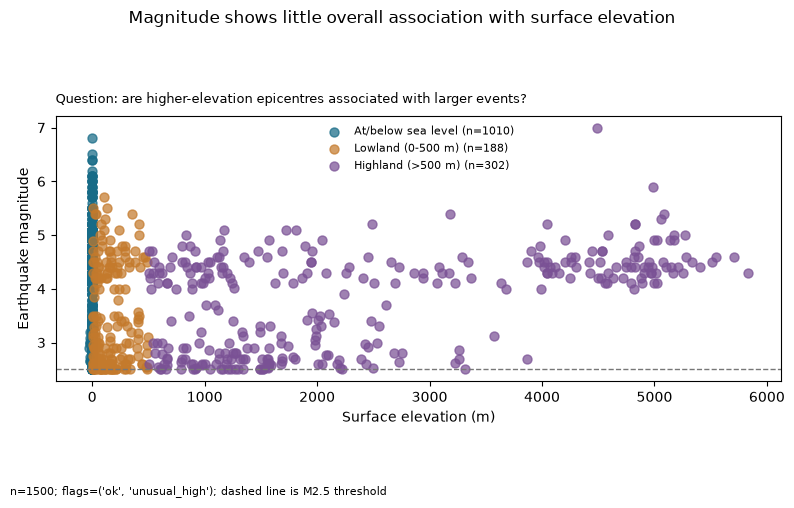

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = {"At/below sea level": "#176B87", "Lowland (0-500 m)": "#C47A2C", "Highland (>500 m)": "#7A5195"}
for band, frame in events.groupby("elevation_band", observed=True):
    ax.scatter(frame.elevation, frame.magnitude, alpha=.72, s=42, label=f"{band} (n={len(frame)})", color=colors[str(band)])
ax.axhline(2.5, color="#777777", linestyle="--", linewidth=1)
fig.suptitle("Magnitude shows little overall association with surface elevation", y=.98)
ax.set_title("Question: are higher-elevation epicentres associated with larger events?", loc="left", fontsize=9, pad=9)
ax.set(xlabel="Surface elevation (m)", ylabel="Earthquake magnitude")
ax.legend(frameon=False, fontsize=8)
fig.text(0.01, 0.01, f"n={len(events)}; flags={MAGNITUDE_FLAGS_REPORTED}; dashed line is M2.5 threshold", fontsize=8)
fig.tight_layout(rect=(0, .12, 1, .91))
fig.savefig(FIGURE_DIR / "magnitude_vs_elevation.png", dpi=180, bbox_inches="tight")

In [8]:
overall_pearson = pearsonr(events.magnitude, events.elevation)
overall_spearman = spearmanr(events.magnitude, events.elevation)
cutoff = events.elevation.quantile(.975)
without_highest = events.loc[events.elevation <= cutoff]
events["spatial_cell"] = (
    np.floor(events.latitude / SPATIAL_GRID_DEGREES).astype(int).astype(str)
    + "_" + np.floor(events.longitude / SPATIAL_GRID_DEGREES).astype(int).astype(str)
)
largest_cell = events.spatial_cell.value_counts().idxmax()
without_largest_cell = events.loc[events.spatial_cell != largest_cell]

relationship = pd.DataFrame([
    {"check": "All usable events", "n": len(events), "pearson_r": overall_pearson.statistic, "spearman_rho": overall_spearman.statistic},
    {"check": "Exclude top 2.5% elevation", "n": len(without_highest), "pearson_r": pearsonr(without_highest.magnitude, without_highest.elevation).statistic, "spearman_rho": spearmanr(without_highest.magnitude, without_highest.elevation).statistic},
    {"check": f"Exclude largest 10-degree cell ({largest_cell})", "n": len(without_largest_cell), "pearson_r": pearsonr(without_largest_cell.magnitude, without_largest_cell.elevation).statistic, "spearman_rho": spearmanr(without_largest_cell.magnitude, without_largest_cell.elevation).statistic},
])
display(relationship.round(3))

within = []
for band, frame in events.groupby("elevation_band", observed=True):
    within.append({"band": band, "n": len(frame),
                   "pearson_r": pearsonr(frame.magnitude, frame.elevation).statistic,
                   "spearman_rho": spearmanr(frame.magnitude, frame.elevation).statistic})
display(pd.DataFrame(within).round(3))

,check,n,pearson_r,spearman_rho
0,All usable events,1500,0.076,-0.127
1,Exclude top 2.5% elevation,1462,0.004,-0.173
2,Exclude largest 10-degree cell (-2_16),1308,0.147,-0.035


,band,n,pearson_r,spearman_rho
0,At/below sea level,1010,0.108,0.097
1,Lowland (0-500 m),188,0.030,0.044
2,Highland (>500 m),302,0.497,0.413


The overall coefficients are close to zero, but sensitivity checks move them, and within-band coefficients have different signs/magnitudes from the overall result. This instability, the ocean-surface limitation, and the short event window argue against a general relationship claim.

## 2.7 One comparison, with an interval and a count of looks

The chosen comparison is mean magnitude in highland versus at/below-sea-level locations. Three pairwise band comparisons were inspected before selecting this question. To reduce false precision from clustered earthquakes, the resampling unit is a 10-degree latitude-longitude cell: events are averaged within cells, then cells are resampled within each band. Grid cells are not perfectly independent, but they are more defensible than treating 1,500 individual events as independent.

,0
comparison,Highland - at/below sea level
highland_events,302
sea_level_events,1010
highland_cells,55
sea_level_cells,89
difference_cell_mean_magnitude,-0.396
ci_2.5%,-0.629
ci_97.5%,-0.167
comparisons_explored,3


,event_time,elevation_band,n,mean
0,2026-10-22 00:00:00+00:00,At/below sea level,33,4.033
1,2026-10-22 00:00:00+00:00,Lowland (0-500 m),5,3.176
2,2026-10-22 00:00:00+00:00,Highland (>500 m),27,4.557
3,2026-10-23 00:00:00+00:00,At/below sea level,37,4.153
4,2026-10-23 00:00:00+00:00,Lowland (0-500 m),8,3.616
...,...,...,...,...
70,2026-11-14 00:00:00+00:00,Lowland (0-500 m),7,3.586
71,2026-11-14 00:00:00+00:00,Highland (>500 m),8,3.719
72,2026-11-15 00:00:00+00:00,At/below sea level,14,4.039
73,2026-11-15 00:00:00+00:00,Lowland (0-500 m),6,3.217


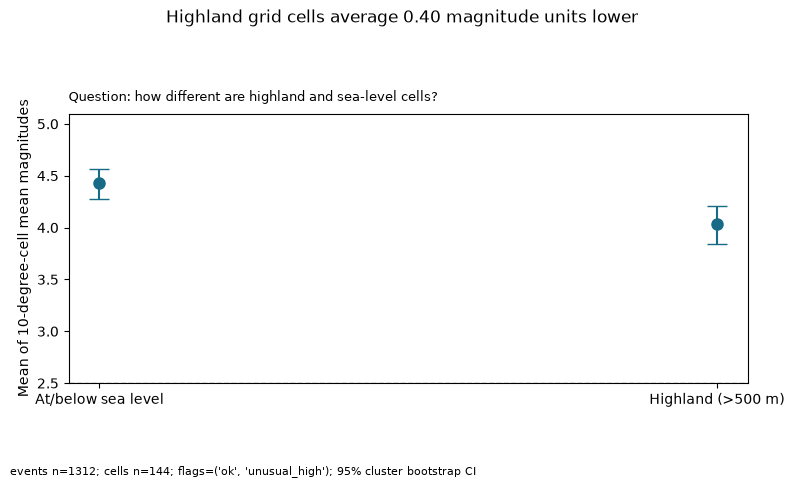

In [9]:
cell_means = events.groupby(["elevation_band", "spatial_cell"], observed=True).magnitude.mean().reset_index()
sea = cell_means.loc[cell_means.elevation_band == "At/below sea level", "magnitude"].to_numpy()
high = cell_means.loc[cell_means.elevation_band == "Highland (>500 m)", "magnitude"].to_numpy()
rng = np.random.default_rng(RANDOM_SEED)
bootstrap = np.array([
    rng.choice(high, len(high), replace=True).mean() - rng.choice(sea, len(sea), replace=True).mean()
    for _ in range(BOOTSTRAP_REPS)
])
difference = high.mean() - sea.mean()
ci_low, ci_high = np.quantile(bootstrap, [.025, .975])
comparison = pd.DataFrame({
    "comparison": ["Highland - at/below sea level"],
    "highland_events": [(events.elevation_band == "Highland (>500 m)").sum()],
    "sea_level_events": [(events.elevation_band == "At/below sea level").sum()],
    "highland_cells": [len(high)], "sea_level_cells": [len(sea)],
    "difference_cell_mean_magnitude": [difference],
    "ci_2.5%": [ci_low], "ci_97.5%": [ci_high],
    "comparisons_explored": [COMPARISONS_EXPLORED],
})
display(comparison.round(3).T)

composition = events.groupby([events.event_time.dt.floor("D"), "elevation_band"], observed=True).magnitude.agg(n="count", mean="mean").reset_index()
display(composition.assign(mean=composition["mean"].round(3)))

fig, ax = plt.subplots(figsize=(8, 4.8))
labels = ["At/below sea level", "Highland (>500 m)"]
means = [sea.mean(), high.mean()]
cell_boot = []
for values in [sea, high]:
    samples = np.array([rng.choice(values, len(values), replace=True).mean() for _ in range(BOOTSTRAP_REPS)])
    cell_boot.append(np.quantile(samples, [.025, .975]))
errors = np.array([[m - ci[0] for m, ci in zip(means, cell_boot)], [ci[1] - m for m, ci in zip(means, cell_boot)]])
ax.errorbar(labels, means, yerr=errors, fmt="o", capsize=7, markersize=8, color="#176B87")
ax.set_ylim(2.5, 5.1)
ax.axhline(2.5, color="#777777", linestyle="--", linewidth=1)
fig.suptitle("Highland grid cells average 0.40 magnitude units lower", y=.98)
ax.set_title("Question: how different are highland and sea-level cells?", loc="left", fontsize=9, pad=9)
ax.set(ylabel="Mean of 10-degree-cell mean magnitudes")
fig.text(0.01, 0.01, f"events n={int((events.elevation_band != 'Lowland (0-500 m)').sum())}; cells n={len(sea)+len(high)}; flags={MAGNITUDE_FLAGS_REPORTED}; 95% cluster bootstrap CI", fontsize=8)
fig.tight_layout(rect=(0, .12, 1, .91))
fig.savefig(FIGURE_DIR / "elevation_group_comparison.png", dpi=180, bbox_inches="tight")

The overall direction is supported on 18 of 25 UTC dates but reverses on seven, so temporal composition and sequence clustering matter even though there is no full Simpson reversal. The event-weighted contrast is smaller than the cell-weighted contrast, also showing spatial composition effects. The interval is exploratory: grid boundaries are arbitrary, only 144 cells enter, this comparison followed three looks, and spatial dependence remains.

## 2.8 Findings, honestly labelled

Contributor names below are verified from Git history. Because this notebook was prepared with coding assistance, the team must review and confirm who can defend each finding before submission; no contribution is attributed as completed without that confirmation.

In [10]:
findings = pd.DataFrame([
    ["F-01", "Mean magnitude is 3.887 in both raw and cleaned layers (n=1,500 each).", "Raw/clean SQL output", "Exploratory", "A later snapshot with duplicates or invalid values", "Pending team confirmation: Aysima Tatlı"],
    ["F-02", "At/below-sea-level events have the highest mean and median magnitude in this snapshot.", "magnitude_ecdf_by_elevation.png; group table", "Exploratory", "A longer fixed observation window or seafloor elevation", "Pending team confirmation: Umut Siar Demir"],
    ["F-03", "Overall magnitude-elevation association is near zero and sensitivity-dependent.", "magnitude_vs_elevation.png; correlation table", "Exploratory", "More events, fault/depth controls, or a stable coefficient", "Pending team confirmation: Yaşar Kaki"],
    ["F-04", "Highland cells average 0.396 magnitude units below sea-level cells (95% bootstrap CI -0.629 to -0.167).", "elevation_group_comparison.png", "Exploratory", "Different grid scale, window, or spatially explicit resampling", "Pending review by all three verified members"],
], columns=["ID", "Finding", "Evidence", "Label", "What would change it", "Explored by"])
display(findings)

,ID,Finding,Evidence,Label,What would change it,Explored by
0,F-01,Mean magnitude is 3.887 in both raw and cleane...,Raw/clean SQL output,Exploratory,A later snapshot with duplicates or invalid va...,Pending team confirmation: Aysima Tatlı
1,F-02,At/below-sea-level events have the highest mea...,magnitude_ecdf_by_elevation.png; group table,Exploratory,A longer fixed observation window or seafloor ...,Pending team confirmation: Umut Siar Demir
2,F-03,Overall magnitude-elevation association is nea...,magnitude_vs_elevation.png; correlation table,Exploratory,"More events, fault/depth controls, or a stable...",Pending team confirmation: Yaşar Kaki
3,F-04,Highland cells average 0.396 magnitude units b...,elevation_group_comparison.png,Exploratory,"Different grid scale, window, or spatially exp...",Pending review by all three verified members


### Back to cleaning

- The hardcoded İzmir event-to-location mapping was a real M2/M3 defect. It was fixed in ingestion/loading, documented in the cleaning report, and protected by a regression test.
- No additional invalid values were found in this recovered snapshot. Zero-metre marine elevations remain valid API outputs but are a scientific measurement limitation, not silently recoded missingness.

### Forward to modelling

- Use a fixed, longer collection window; incorporate hypocentral depth, tectonic plate/fault proximity, and ocean bathymetry.
- Use spatially blocked validation and sequence-aware grouping so aftershocks do not leak across train/test partitions.
- Treat the M2.5 threshold and latest-1,500 sampling mechanism as selection effects.

### What we cannot say

This snapshot cannot establish causation, long-run global frequency, seasonality, holiday effects, or a stable elevation-magnitude relationship. It excludes earthquakes below M2.5, covers about 24.3 days, has partial edge periods, and uses surface elevation at epicentres. The confidence interval does not repair those design limitations or the fact that three comparisons were explored.

In [11]:
con.close()
DB_HASH_AFTER = sha256(DB_PATH)
print({"db_sha256_before": DB_HASH_BEFORE, "db_sha256_after": DB_HASH_AFTER,
       "database_unchanged": DB_HASH_BEFORE == DB_HASH_AFTER,
       "figures": sorted(path.name for path in FIGURE_DIR.glob("*.png"))})
assert DB_HASH_BEFORE == DB_HASH_AFTER, "Read-only analysis changed the database"

{'db_sha256_before': '27b390687164337d9685d3fc58b9fd95881b777a0b43ce1c9080711b9c0b31e3', 'db_sha256_after': '27b390687164337d9685d3fc58b9fd95881b777a0b43ce1c9080711b9c0b31e3', 'database_unchanged': True, 'figures': ['coverage.png', 'elevation_group_comparison.png', 'magnitude_ecdf_by_elevation.png', 'magnitude_histogram.png', 'magnitude_vs_elevation.png', 'temporal_counts_utc.png']}
